In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

%matplotlib inline

## Import Libraries

- __pandas__ and __numpy__ for data loading, manipulation, and numerical operations

- __matplotlib__ and __seaborn__ for data visualisation

- __scikit-learn__ for the machine learning workflow:
  - `MinMaxScaler` scales features to a common range
  - `train_test_split` splits the data into training and test sets
  - `GridSearchCV` finds the best hyperparameters using cross-validation
  - `KNeighborsClassifier` is the K-Nearest Neighbours classification model
  - `accuracy_score`, `confusion_matrix`, and `ConfusionMatrixDisplay` for evaluation and visualisation of model performance

`%matplotlib inline` to render plots inside the notebook.

In [11]:
ds = pd.read_csv("heart_dataset.csv")
ds.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [12]:
ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [13]:
#Resting BP & Cholesterol are abnormal
ds.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [16]:
#Checking for missing values
ds.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [17]:
#Removing duplicated values if any
ds = ds.drop_duplicates()

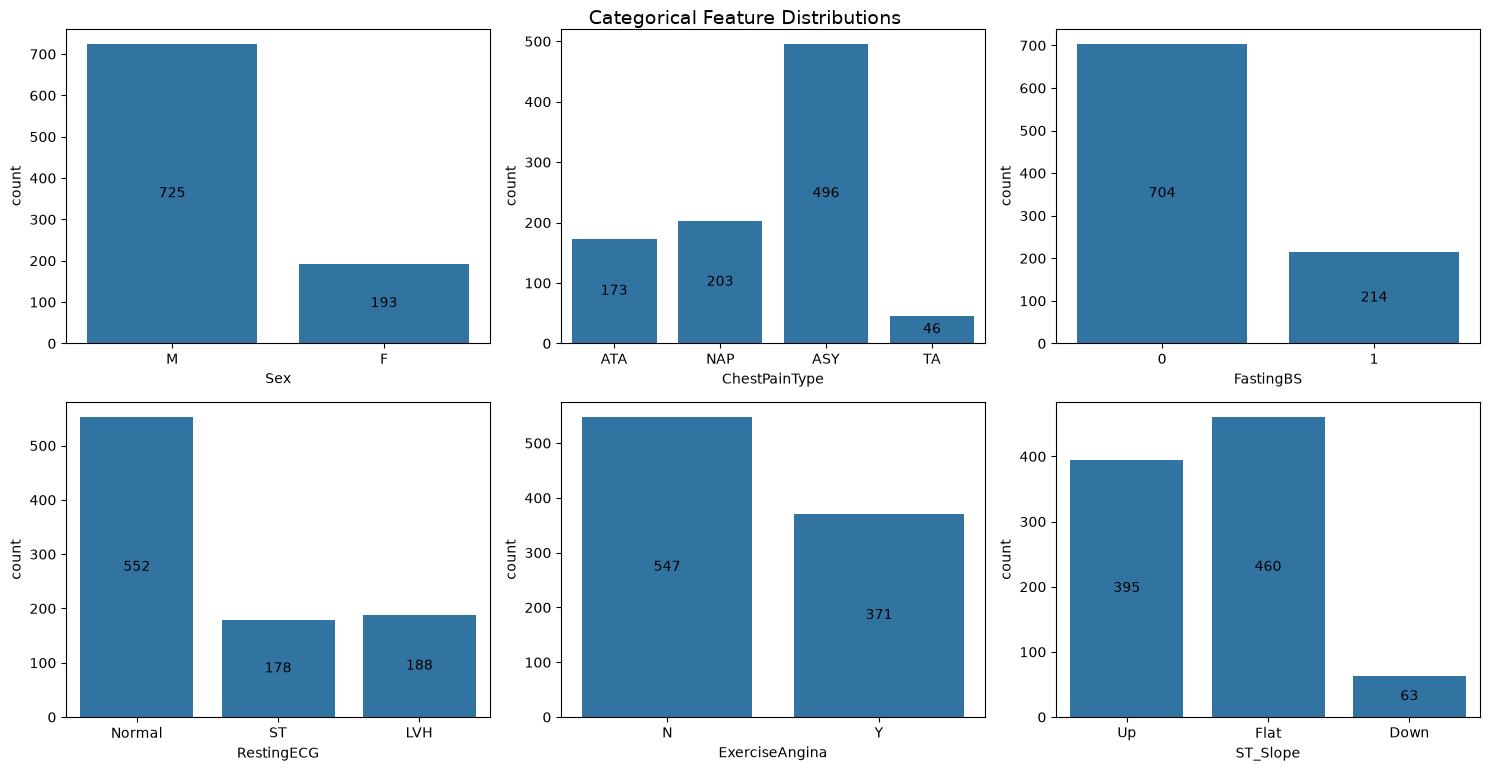

In [83]:
#Divide data types into numeric or categorical
categorical = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease']

from pathlib import Path
Path("datastore").mkdir(exist_ok=True)

#Bar charts to visualize the categories
fig = plt.figure(figsize=(15,15))

for index, column in enumerate(categorical[:-1]):
    ax = plt.subplot(4, 3, index+1)
    sns.countplot(x=ds[column], ax=ax)

    #Adds data labels to each bar
    for container in ax.containers:
        ax.bar_label(container, label_type="center")

plt.suptitle("Categorical Feature Distributions", y=0.98, fontsize=14)
plt.tight_layout()
fig.savefig("datastore/Categorical-Feature-Distribution.png", dpi=150, bbox_inches="tight")
plt.show()

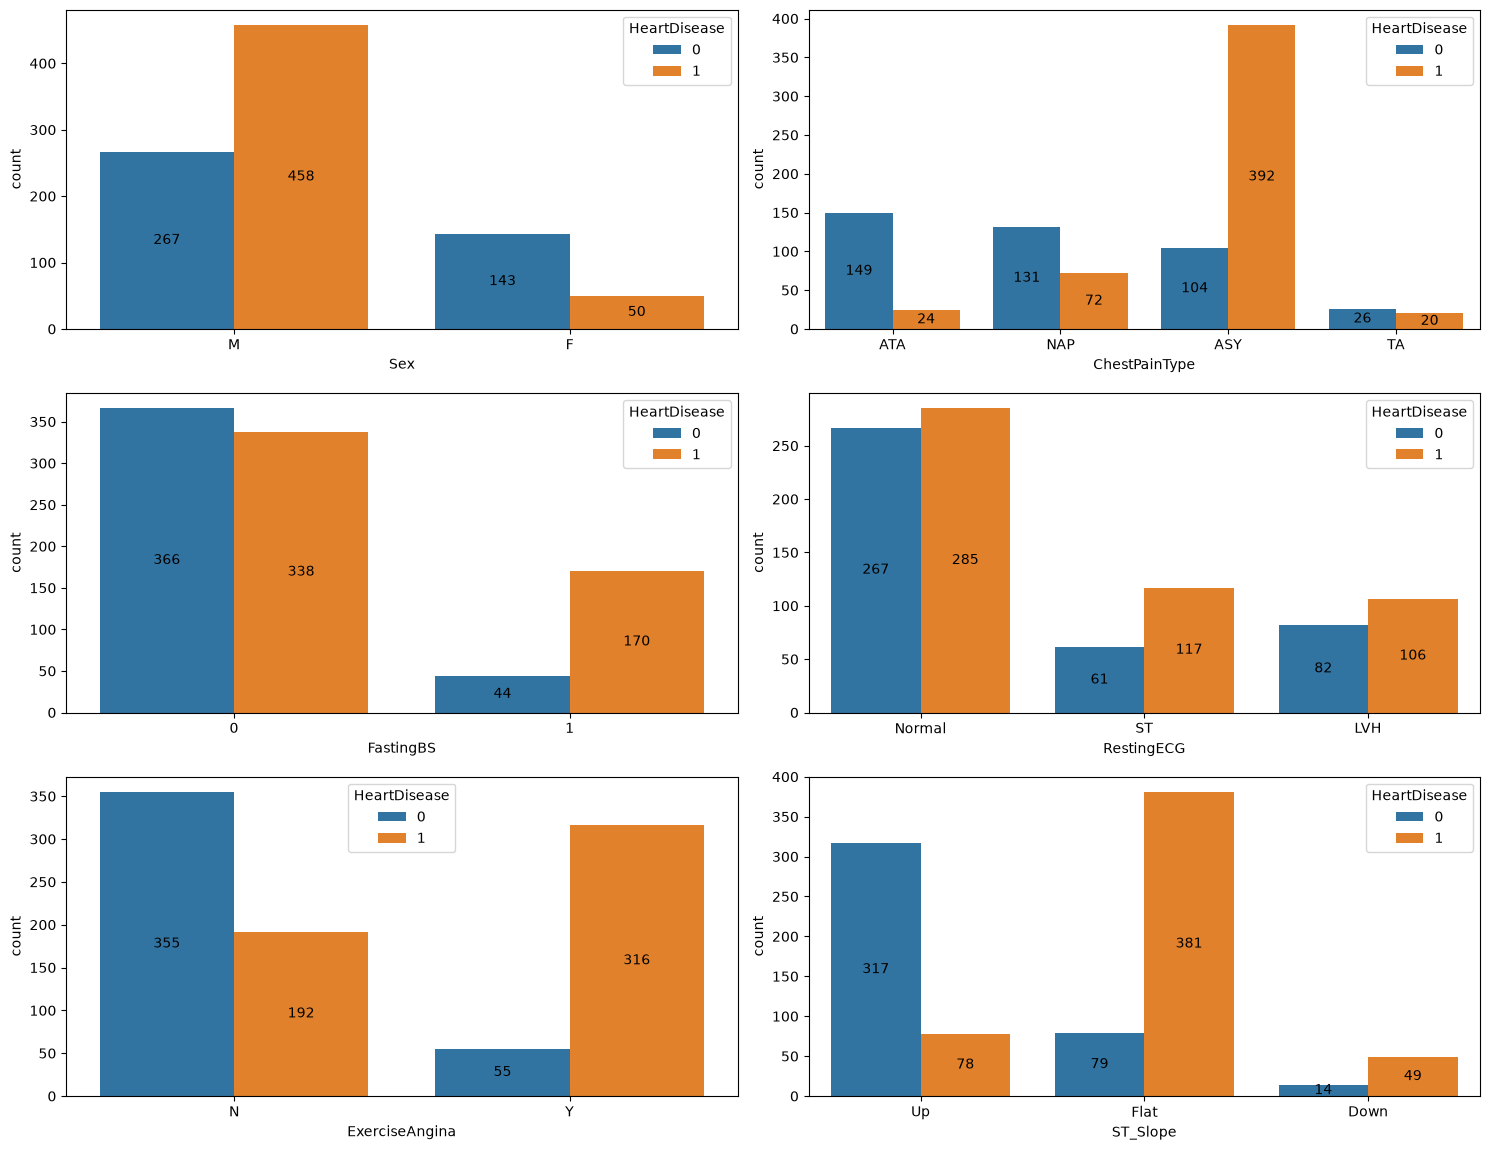

In [86]:
#Comparing diseased and non diseased data
fig = plt.figure(figsize=(15,15))

for index, column in enumerate(categorical[:-1]):
    ax = plt.subplot(4, 2, index +1)
    sns.countplot(x=ds[column], hue=ds["HeartDisease"], ax=ax)
    for container in ax.containers:
        ax.bar_label(container, label_type="center")

plt.tight_layout()
fig.savefig("datastore/Heart-Disease-Comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
#Checking for abnormal values
ds[ds["RestingBP"]==0].info()

<class 'pandas.DataFrame'>
RangeIndex: 1 entries, 449 to 449
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             1 non-null      int64  
 1   Sex             1 non-null      str    
 2   ChestPainType   1 non-null      str    
 3   RestingBP       1 non-null      int64  
 4   Cholesterol     1 non-null      int64  
 5   FastingBS       1 non-null      int64  
 6   RestingECG      1 non-null      str    
 7   MaxHR           1 non-null      int64  
 8   ExerciseAngina  1 non-null      str    
 9   Oldpeak         1 non-null      float64
 10  ST_Slope        1 non-null      str    
 11  HeartDisease    1 non-null      int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 228.0 bytes


In [29]:
#Checking for abnormal values
ds[ds["Cholesterol"]==0].info()

<class 'pandas.DataFrame'>
Index: 172 entries, 293 to 536
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             172 non-null    int64  
 1   Sex             172 non-null    str    
 2   ChestPainType   172 non-null    str    
 3   RestingBP       172 non-null    int64  
 4   Cholesterol     172 non-null    int64  
 5   FastingBS       172 non-null    int64  
 6   RestingECG      172 non-null    str    
 7   MaxHR           172 non-null    int64  
 8   ExerciseAngina  172 non-null    str    
 9   Oldpeak         172 non-null    float64
 10  ST_Slope        172 non-null    str    
 11  HeartDisease    172 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 17.5 KB


In [37]:
#Replacing with median valuues according to whether they have heart disease or not
ds_clean = ds.copy()


ds_clean = ds_clean[ds_clean["RestingBP"] != 0]

heartdisease_mask = ds_clean["HeartDisease"] == 0

#Replacing zero values with median cholesterol
def zero_clean(data):
    median_val = data[data != 0].median()
    return data.replace(0, median_val)

ds_clean['Cholesterol'] = (ds_clean.groupby('HeartDisease')['Cholesterol'].transform(zero_clean))

In [38]:
#Checking the minimum values
ds_clean[['Cholesterol', 'RestingBP']].describe()

,Cholesterol,RestingBP
count,917.000000,917.000000
mean,244.573610,132.540894
std,53.385261,17.999749
min,85.000000,80.000000
25%,214.000000,120.000000
50%,246.000000,130.000000
75%,267.000000,140.000000
max,603.000000,200.000000


In [40]:
#Transforming the categorical values into boolean values
ds_clean = pd.get_dummies(ds_clean, drop_first=True)
ds_clean.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True


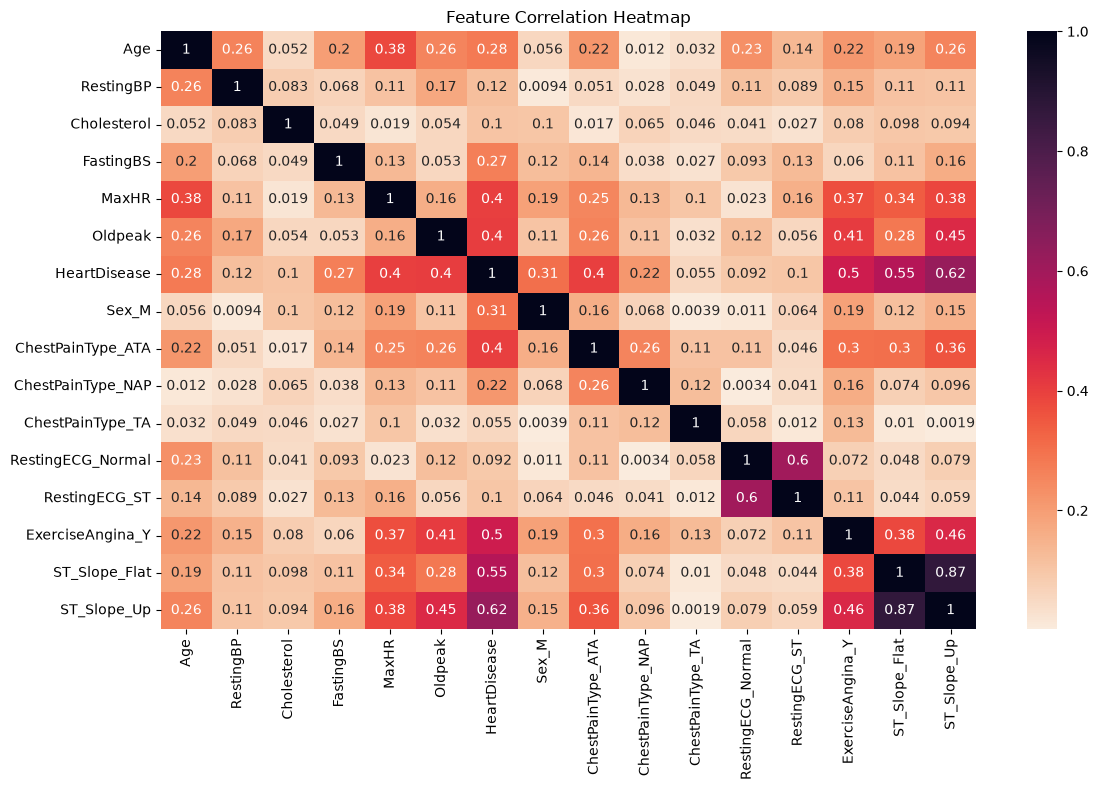

In [82]:
#Checking the correlation using a heatmap
correlations = abs(ds_clean.corr())
plt.figure(figsize=(12,8))
sns.heatmap(correlations, annot=True, cmap="rocket_r")

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("datastore/correlation-heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

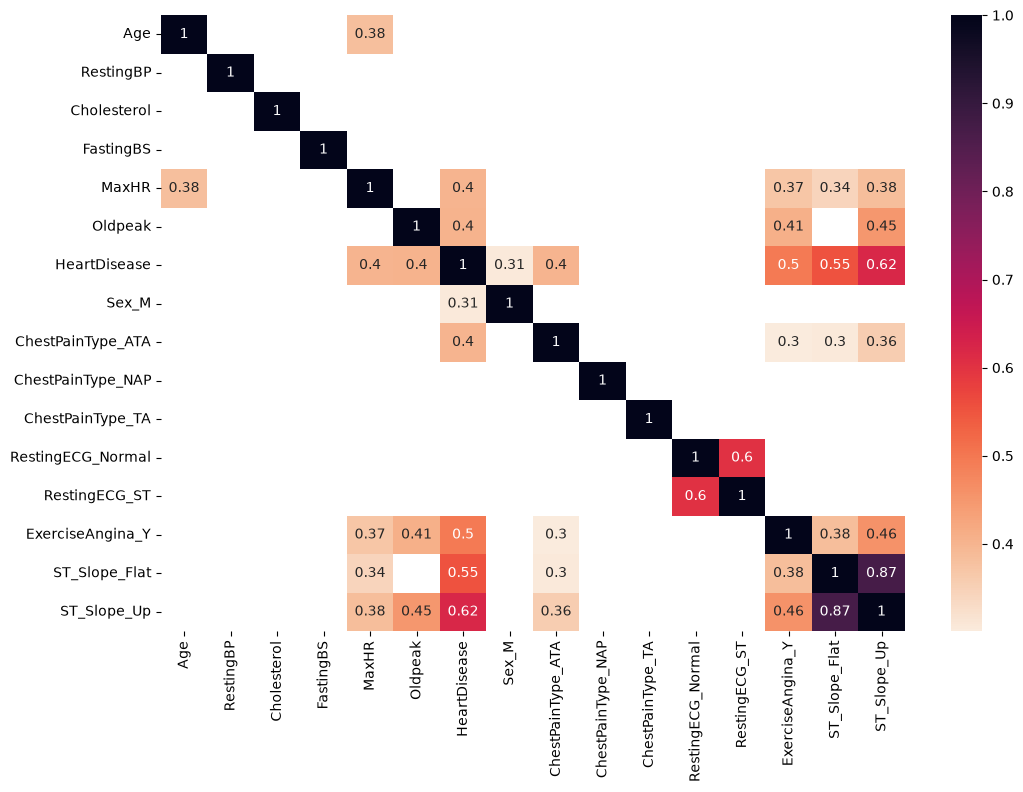

In [44]:
#Filtering for key values to use as training data
plt.figure(figsize=(12,8)) 
sns.heatmap(correlations[correlations>0.30], annot=True, cmap='rocket_r')
plt.show()

In [68]:
#Splitting into train/test datasets
X = ds_clean.drop(["HeartDisease"], axis=1)
y = ds_clean["HeartDisease"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.15, random_state= 417)

In [69]:
#Training data by each feature
features = [
    "MaxHR",
    "Oldpeak", 
    "Sex_M", 
    "ExerciseAngina_Y", 
    "ST_Slope_Flat", 
    "ST_Slope_Up"]

for feature in features:
    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(X_train[[feature]], y_train)
    accuracy = knn.score(X_val[[feature]], y_val)
    print(f'The k-NN classifier trained on {feature} and with k = 3 has an accuracy of {accuracy*100:.2f}%')

The k-NN classifier trained on MaxHR and with k = 3 has an accuracy of 55.07%
The k-NN classifier trained on Oldpeak and with k = 3 has an accuracy of 58.70%
The k-NN classifier trained on Sex_M and with k = 3 has an accuracy of 61.59%
The k-NN classifier trained on ExerciseAngina_Y and with k = 3 has an accuracy of 73.19%
The k-NN classifier trained on ST_Slope_Flat and with k = 3 has an accuracy of 81.88%
The k-NN classifier trained on ST_Slope_Up and with k = 3 has an accuracy of 55.07%


In [70]:
#Training data by all features

#Normalise numerical features to a fixed range for model training
scaler = MinMaxScaler() 

X_train_scaled = scaler.fit_transform(X_train[features])
X_val_scaled = scaler.transform(X_val[features])

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)
accuracy = knn.score(X_val_scaled, y_val)
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 83.33%


In [71]:
#Training data with some of the features removed

Xt = ds_clean.drop(["HeartDisease"], axis=1)
yt = ds_clean['HeartDisease']

Xt_train, Xt_test, yt_train, yt_test = train_test_split(Xt, yt, test_size=0.15, random_state=417)

features = ["MaxHR", 
            "Oldpeak", 
            "ExerciseAngina_Y",
            #"Sex_M", 
            "ST_Slope_Flat",
            "ST_Slope_Up"]

scaler = MinMaxScaler()
Xt_train_scaled = scaler.fit_transform(Xt_train[features])
Xt_train_scaled

array([[0.78169014, 0.42682927, 0.        , 0.        , 1.        ],
       [0.46478873, 0.42682927, 1.        , 1.        , 0.        ],
       [0.71126761, 0.48780488, 0.        , 1.        , 0.        ],
       ...,
       [0.26056338, 0.51219512, 1.        , 0.        , 1.        ],
       [0.15492958, 0.19512195, 0.        , 0.        , 1.        ],
       [0.59859155, 0.63414634, 0.        , 1.        , 0.        ]],
      shape=(779, 5))

In [72]:
grid_params = {"n_neighbors": range(1,20),
               "metric": ['minkowski', 'manhattan']}

knn = KNeighborsClassifier()
knn_grid = GridSearchCV(knn, grid_params, scoring='accuracy')
knn_grid.fit(Xt_train_scaled, yt_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'metric': ['minkowski', 'manhattan'], 'n_neighbors': range(1, 20)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of in

In [73]:
knn_grid.best_score_*100, knn_grid.best_params_

(np.float64(82.66749379652605), {'metric': 'manhattan', 'n_neighbors': 19})

In [74]:
Xt_test_scaled = scaler.transform(Xt_test[features])
predictions = knn_grid.best_estimator_.predict(Xt_test_scaled)
accuracy = accuracy_score(yt_test, predictions)
print(f"Model accuracy on test: {accuracy*100:.2f}%")

Model accuracy on test: 82.61%


In [75]:
#Checking data distribution
print("Distribution of patients by their sex in the entire dataset")
print(X.Sex_M.value_counts()) 

Distribution of patients by their sex in the entire dataset
Sex_M
True     724
False    193
Name: count, dtype: int64


In [76]:
print("Distribution of patients by their sex int the training dataset")
print(X_train.Sex_M.value_counts())

Distribution of patients by their sex int the training dataset
Sex_M
True     615
False    164
Name: count, dtype: int64


In [77]:
print('Distribution of patients by their sex in the test dataset')  
print(Xt_test.Sex_M.value_counts())

Distribution of patients by their sex in the test dataset
Sex_M
True     109
False     29
Name: count, dtype: int64


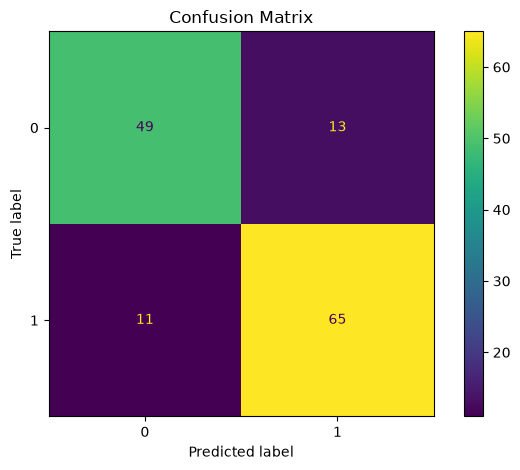

In [81]:
#Confusion Matrix comparing y-test by prediction values
cf = confusion_matrix(yt_test, predictions)
ConfusionMatrixDisplay(cf).plot()

plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("datastore/Confusion-Matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [91]:
from xgboost import XGBClassifier

Xt2 = ds_clean.drop(["HeartDisease"], axis=1)
yt2 = ds_clean['HeartDisease']

Xt2_train, Xt2_test, yt2_train, yt2_test = train_test_split(Xt2, yt2, test_size=0.15, random_state=417)

model = XGBClassifier()

model.fit(Xt2_train,yt2_train)                                                  

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [94]:
yt2_predict = model.predict(Xt2_test)

xg_accuracy = accuracy_score(yt2_test, yt2_predict)
print(f"Accuracy: {xg_accuracy*100:.2f}%")

Accuracy: 86.96%


In [93]:
from sklearn.metrics import classification_report

print(classification_report(yt2_test, yt2_predict))

              precision    recall  f1-score   support

           0       0.89      0.81      0.85        62
           1       0.85      0.92      0.89        76

    accuracy                           0.87       138
   macro avg       0.87      0.86      0.87       138
weighted avg       0.87      0.87      0.87       138



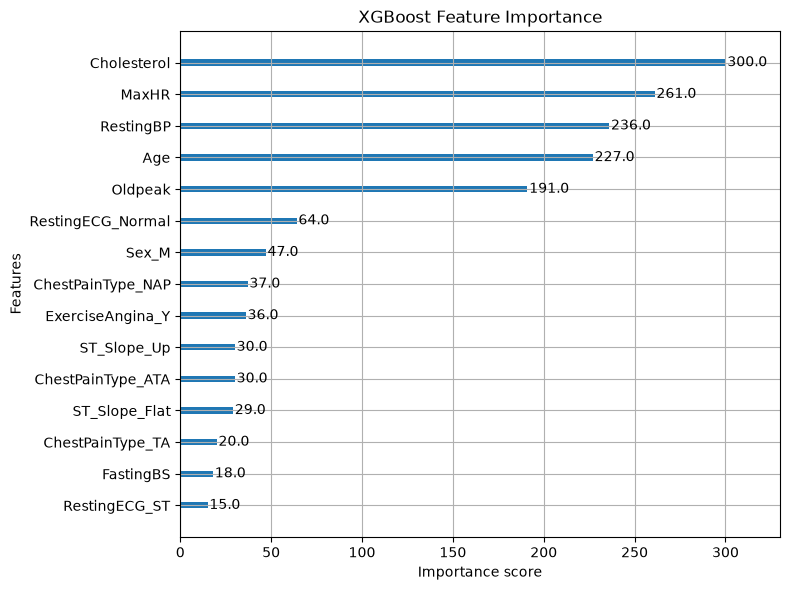

In [96]:
#Plots which features the baseline XGBoost model used most often when splitting
from xgboost import plot_importance

fig, ax = plt.subplots(figsize=(8, 6))
plot_importance(model, ax=ax)

ax.set_title("XGBoost Feature Importance")
plt.tight_layout()
fig.savefig("datastore/xgboost-feature-importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [97]:
model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42)

model.fit(Xt2_train,yt2_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [99]:
yt2_predict = model.predict(Xt2_test)

accuracy = accuracy_score(yt2_test,yt2_predict)
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 90.58%
